# Лабораторна робота 2. Метод Монте-Карло для MountainCar-v0

In [1]:
try:
    import gymnasium as gym
except ImportError:
    %pip install -q "gymnasium[classic-control]" matplotlib
    import gymnasium as gym
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

EPISODES, BATCH = 500_000, 250
HORIZON, EPS_MIN, SEED = 1000, 0.05, 42
EVAL_EPISODES = 1000

lab1 = np.load("lab1_dp_results.npz")   # копія results/dp_results.npz з ЛР1
N_X, N_V, GAMMA = int(lab1["n_x"]), int(lab1["n_v"]), float(lab1["gamma"])

env = gym.make("MountainCar-v0")
car = env.unwrapped
x_edges = np.linspace(car.min_position, car.max_position, N_X + 1)
v_edges = np.linspace(-car.max_speed, car.max_speed, N_V + 1)
N_S = N_X * N_V


def to_state(x, v):
    return np.digitize(x, x_edges[1:-1]) * N_V + np.digitize(v, v_edges[1:-1])


def step(x, v, a):
    """MountainCarEnv.step для масиву візків (та сама функція, що в ЛР1)."""
    v = np.clip(v + (a - 1) * car.force - np.cos(3 * x) * car.gravity, -car.max_speed, car.max_speed)
    x = np.clip(x + v, car.min_position, car.max_position)
    v = np.where((x == car.min_position) & (v < 0), 0.0, v)
    return x, v, (x >= car.goal_position) & (v >= car.goal_velocity)

## Навчання

Для кожного пакета: згенерувати `BATCH` епізодів ε-жадібною політикою, порахувати повернення зворотним проходом G_t = -1 + γ·G_(t+1), взяти перше входження кожної пари (s,a) в епізод і оновити середнє Q(s,a) = Σ G / N(s,a). Агент бачить лише зразки (s, a, r, s'), моделі P він не будує.

In [2]:
rng = np.random.default_rng(SEED)
G_sum, N, N_state = np.zeros((N_S, 3)), np.zeros((N_S, 3)), np.zeros(N_S)
Q = np.zeros((N_S, 3))
curve = []                                   # (епізодів, середня довжина навчального епізоду)

t0 = time.perf_counter()
for batch in range(EPISODES // BATCH):
    x = rng.uniform(car.min_position, car.goal_position, BATCH)      # exploring starts
    v = rng.uniform(-car.max_speed, car.max_speed, BATCH)
    S, A = np.zeros((HORIZON, BATCH), int), np.zeros((HORIZON, BATCH), int)
    alive, valid = np.ones(BATCH, bool), np.zeros((HORIZON, BATCH), bool)
    for t in range(HORIZON):
        s = to_state(x, v)
        explore = (rng.random(BATCH) < np.maximum(EPS_MIN, 1 / (1 + N_state[s]))) | (t == 0)
        a = np.where(explore, rng.integers(0, 3, BATCH), Q[s].argmax(axis=1))
        S[t], A[t], valid[t] = s, a, alive
        x, v, done = step(x, v, a)
        alive &= ~done
        if not alive.any():
            break
    T = t + 1
    G, Gs = np.zeros(BATCH), np.zeros((T, BATCH))
    for k in range(T - 1, -1, -1):
        G = np.where(valid[k], -1 + GAMMA * G, 0.0)
        Gs[k] = G
    use = (valid[:T] & ~alive).ravel()                                # лише епізоди, що дійшли до цілі
    pair = (np.arange(BATCH) * N_S * 3 + S[:T] * 3 + A[:T]).ravel()   # (епізод, s, a)
    _, first = np.unique(np.where(use, pair, -1), return_index=True)  # перше входження в часі
    first = first[use[first]]
    s_, a_ = S[:T].ravel()[first], A[:T].ravel()[first]
    np.add.at(G_sum, (s_, a_), Gs.ravel()[first])
    np.add.at(N, (s_, a_), 1)
    N_state += np.bincount(s_, minlength=N_S)
    Q = np.where(N > 0, G_sum / np.maximum(N, 1), 0.0)
    curve.append(((batch + 1) * BATCH, valid[:T].sum() / BATCH))
train_time = time.perf_counter() - t0
pi_mc = np.where(N > 0, Q, -np.inf).argmax(axis=1)
V_mc = np.where(N > 0, Q, -np.inf).max(axis=1)
print(f"MC: {EPISODES} епізодів за {train_time:.0f} с, кроків середовища {sum(c[1] for c in curve) * BATCH:.2e}")

MC: 500000 епізодів за 50 с, кроків середовища 3.20e+07


## Порівняння з PI і VI

Протокол ЛР1: жадібна політика, справжнє середовище `MountainCar-v0` з лімітом 200 кроків, епізод i стартує з `reset(seed=i)`. Дії порівнюємо на всіх комірках і на комірках, через які проходять траєкторії VI: лише там дія впливає на результат.

                         PI       VI       MC
успіхів                1000     1000      967
середньо кроків       104.7    104.7    171.9

дії MC = дії VI: 63.1% усіх комірок, 64.5% комірок на траєкторіях VI
V_MC - V_VI на траєкторіях VI: середнє -6.85, кореляція 0.967


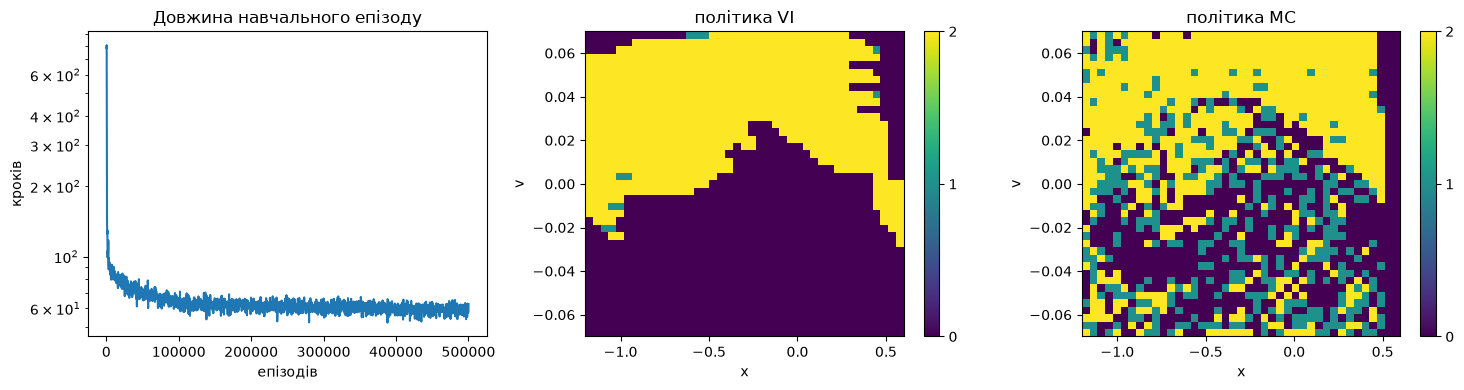

In [3]:
def run(policy, seed, visited=None):
    (x, v), _ = env.reset(seed=seed)
    for t in range(1, 201):
        s = to_state(x, v)
        if visited is not None:
            visited[s] = True
        (x, v), _, term, trunc, _ = env.step(int(policy[s]))
        if term or trunc:
            return term, t


vi_cells = np.zeros(N_S, bool)
res = {"PI": [run(lab1["pi_pi"], i) for i in range(EVAL_EPISODES)],
       "VI": [run(lab1["pi_vi"], i, vi_cells) for i in range(EVAL_EPISODES)],
       "MC": [run(pi_mc, i) for i in range(EVAL_EPISODES)]}
res = {k: np.array(r) for k, r in res.items()}
same = pi_mc == lab1["pi_vi"]
dv = (V_mc - lab1["V_vi"])[vi_cells]

print(f"{'':18}{'PI':>9}{'VI':>9}{'MC':>9}")
print(f"{'успіхів':18}" + "".join(f"{r[:, 0].sum():>9}" for r in res.values()))
print(f"{'середньо кроків':18}" + "".join(f"{r[:, 1].mean():>9.1f}" for r in res.values()))
print(f"\nдії MC = дії VI: {same.mean():.1%} усіх комірок, {same[vi_cells].mean():.1%} комірок на траєкторіях VI")
print(f"V_MC - V_VI на траєкторіях VI: середнє {dv.mean():.2f}, кореляція {np.corrcoef(V_mc[vi_cells], lab1['V_vi'][vi_cells])[0, 1]:.3f}")

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(*zip(*curve))
ax[0].set(title="Довжина навчального епізоду", xlabel="епізодів", ylabel="кроків", yscale="log")
ext = [car.min_position, car.max_position, -car.max_speed, car.max_speed]
for a_, pol, title in [(ax[1], lab1["pi_vi"], "політика VI"), (ax[2], pi_mc, "політика MC")]:
    im = a_.imshow(pol.reshape(N_X, N_V).T, origin="lower", aspect="auto", extent=ext)
    a_.set(title=title, xlabel="x", ylabel="v")
    fig.colorbar(im, ax=a_, ticks=[0, 1, 2])
plt.tight_layout()
plt.show()

In [4]:
OUT = Path("results")
OUT.mkdir(parents=True, exist_ok=True)
summary = {
    "config": {"episodes": EPISODES, "batch": BATCH, "horizon": HORIZON, "eps_min": EPS_MIN, "seed": SEED,
               "gamma": GAMMA, "n_x": N_X, "n_v": N_V},
    "training": {"time_s": train_time, "env_steps": int(sum(c[1] for c in curve) * BATCH),
                 "unvisited_states": int((N.sum(axis=1) == 0).sum())},
    "evaluation": {k: {"episodes": EVAL_EPISODES, "successes": int(r[:, 0].sum()), "mean_steps": float(r[:, 1].mean())}
                   for k, r in res.items()},
    "comparison": {"agreement_all_pct": float(same.mean() * 100), "agreement_vi_path_pct": float(same[vi_cells].mean() * 100),
                   "vi_path_cells": int(vi_cells.sum()), "v_diff_mean": float(dv.mean()),
                   "v_corr": float(np.corrcoef(V_mc[vi_cells], lab1["V_vi"][vi_cells])[0, 1])},
}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2, ensure_ascii=False), encoding="utf-8")

801

## Висновки

PI і VI отримують політику з моделі за частки секунди. MC тієї моделі не має і витрачає десятки мільйонів кроків середовища, щоб оцінити Q з досвіду. Без exploring starts і довшого горизонту навчальні епізоди не доходять до цілі, і MC не отримує жодного сигналу про неї.

Політика MC доходить до цілі зі стандартних стартів, але за більше кроків, ніж PI і VI. Дії MC збігаються з VI лише частково: Q з досвіду - зашумлене середнє, а ε_min = 0.05 означає, що MC оцінює ε-м’яку політику, а не оптимальну, тому V_MC нижча за V_VI.